# FarmTech Solutions – Visão computacional com YOLO: vacas × tratores

**Curso:** Tecnologia em Inteligência Artificial – FIAP
**Atividade:** PBL Fase 6 – Entregas 1 e 2 (redes neurais e visão computacional)
**Aluno:** Ronaldo Keity Sieg Nishime – RM571759

---

## Sumário

1. Contexto e objetivos
2. Configuração do ambiente (Google Colab + Google Drive)
3. A base de imagens: coleta, organização e rotulação no Make Sense
4. **Entrega 1** – YOLOv5 customizado: treinamento, validação e teste (30 × 30 épocas)
5. **Entrega 2** – YOLO customizado × YOLO padrão × CNN treinada do zero
6. Conclusões, pontos fortes e limitações
7. Salvando os resultados no Drive
8. Referências e créditos das imagens

## 1. Contexto e objetivos

A FarmTech Solutions ampliou sua carteira para saúde animal, segurança patrimonial de fazendas e visão computacional. Neste notebook, o time de desenvolvimento demonstra a um cliente fictício, um produtor rural com rebanho bovino e frota de máquinas, **como funciona na prática um sistema de visão computacional** que reconhece dois objetos bem diferentes:

| Classe | Objeto | Por que interessa ao cliente |
|---|---|---|
| `vaca` (A) | bovinos domésticos (vacas, bezerros, bois) | contagem e monitoramento do rebanho, base para aplicações de saúde animal (animal caído, fora do pasto, perto da cerca) |
| `trator` (B) | tratores agrícolas | rastreio da frota, uso fora de horário, segurança patrimonial do galpão e das lavouras |

Os dois objetos são deliberadamente distintos (um animal de formas orgânicas e pelagem variada × uma máquina rígida, com rodas e cabine), como pede o enunciado. Há ainda um ingrediente que torna a comparação da Entrega 2 interessante: a YOLO pré-treinada no COCO **conhece a classe `cow`, mas não tem nenhuma classe de trator**.

**Objetivos**

- **Entrega 1:** organizar a base (40 + 40 imagens, 32/4/4 por classe) no Google Drive, com rótulos no formato do Make Sense, treinar uma YOLOv5 customizada em duas simulações (30 e 30 épocas) e comparar acurácia, erro e desempenho na validação e no teste.
- **Entrega 2:** comparar a YOLO customizada com a **YOLO padrão** (pesos do COCO, sem customização) e com uma **CNN treinada do zero** para classificar a imagem, em facilidade de uso, precisão, tempo de treinamento e tempo de inferência.

## 2. Configuração do ambiente

O notebook foi escrito para o **Google Colab conectado ao Google Drive**: a base de imagens e os rótulos ficam no Drive (`MyDrive/FIAP/fase6_farmtech`) e os resultados do treino voltam para lá ao final.

Para que qualquer pessoa consiga reproduzir a execução (inclusive a equipe de correção, que não tem acesso ao meu Drive), a célula abaixo segue três caminhos:

1. **No Colab, com a pasta no Drive:** monta o Drive e usa a base de lá (fluxo principal).
2. **No Colab, sem a pasta no Drive:** baixa a mesma base do repositório público do GitHub.
3. **Fora do Colab (Jupyter local):** usa a pasta onde o notebook está.

> Dica: no Colab, ative a GPU em *Ambiente de execução → Alterar o tipo de ambiente de execução → GPU T4*. Sem GPU tudo funciona, só que o treino fica bem mais lento (a execução salva neste notebook foi feita em CPU).

In [1]:
# ---- 2.1 Conexão com o Google Drive e definição das pastas do projeto ----
import os, sys, re, time, shutil, subprocess, platform, random, glob   # bibliotecas padrão usadas ao longo do notebook
from pathlib import Path                                               # caminhos independentes do sistema operacional

EM_COLAB = "google.colab" in sys.modules                               # True quando o notebook roda no Google Colab
REPO_GITHUB = "https://github.com/ronishime/fiap-fase6-pbl-farmtech.git"  # repositório público com a mesma base (plano B)

if EM_COLAB:
    from google.colab import drive                                     # API do Colab para acessar o Google Drive
    drive.mount("/content/drive")                                      # monta o Drive (pede autorização na primeira vez)
    PASTA_PROJETO = Path("/content/drive/MyDrive/FIAP/fase6_farmtech")  # pasta do projeto dentro do Drive
    if not (PASTA_PROJETO / "dataset").exists():                       # quem não tem a pasta no Drive...
        print("Base não encontrada no Drive: baixando do GitHub...")
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO_GITHUB, "/content/fase6"], check=True)
        PASTA_PROJETO = Path("/content/fase6")                         # ...usa a cópia do repositório
    PASTA_TRABALHO = Path("/content")                                  # disco local da máquina do Colab (código do YOLOv5)
else:
    PASTA_PROJETO = Path.cwd()                                         # execução local: pasta do próprio notebook
    PASTA_TRABALHO = PASTA_PROJETO

PASTA_BASE = PASTA_PROJETO / "dataset"                                 # base principal (train/val/test)
PASTA_EXTRA = PASTA_PROJETO / "dataset_teste_extra"                    # 40 imagens extras usadas só na Entrega 2
PASTA_RESULTADOS = PASTA_PROJETO / "resultados"                        # métricas, pesos e figuras persistidos
PASTA_FIGURAS = PASTA_PROJETO / "assets"                               # figuras usadas no README
PASTA_LOGS = PASTA_RESULTADOS / "logs"                                 # logs completos dos scripts do YOLOv5
for p in (PASTA_RESULTADOS, PASTA_FIGURAS, PASTA_LOGS):
    p.mkdir(parents=True, exist_ok=True)                               # cria as pastas de saída se não existirem
print("Pasta do projeto:", PASTA_PROJETO)

Pasta do projeto: D:\FIAP\fase_6_cap_1


In [2]:
# ---- 2.2 Código do YOLOv5 (repositório oficial da Ultralytics) ----
PASTA_YOLO = PASTA_TRABALHO / "yolov5"                                 # onde o repositório fica clonado
if not PASTA_YOLO.exists():                                            # clona só na primeira execução
    subprocess.run(["git", "clone", "-q", "https://github.com/ultralytics/yolov5", str(PASTA_YOLO)], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(PASTA_YOLO / "requirements.txt")], check=True)  # dependências
versao = subprocess.run(["git", "log", "-1", "--format=%h (%ad)", "--date=short"], cwd=PASTA_YOLO,
                        capture_output=True, text=True).stdout.strip()  # commit usado, para reprodutibilidade
print("YOLOv5 pronto em", PASTA_YOLO, "| commit", versao)

YOLOv5 pronto em D:\FIAP\fase_6_cap_1\yolov5 | commit f957879 (2026-10-06)


In [3]:
# ---- 2.3 Bibliotecas, versões e hardware ----
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"                               # silencia mensagens informativas do TensorFlow
import numpy as np                                                     # cálculo numérico
import pandas as pd                                                    # tabelas de resultados
import matplotlib.pyplot as plt                                        # gráficos
import matplotlib.patches as patches                                   # retângulos (caixas) sobre as imagens
from PIL import Image                                                  # leitura de imagens
import torch                                                           # PyTorch (base do YOLOv5)
from io import BytesIO                                                 # figuras em memória
from IPython.display import Image as ImagemIPy, display                # exibição de imagens e tabelas

SEMENTE = 42                                                           # semente para reprodutibilidade
random.seed(SEMENTE); np.random.seed(SEMENTE); torch.manual_seed(SEMENTE)
CLASSES = ["vaca", "trator"]                                           # índice 0 = vaca, 1 = trator (mesma ordem do Make Sense)
DISPOSITIVO = "0" if torch.cuda.is_available() else "cpu"              # GPU 0 se houver, senão CPU
HARDWARE = torch.cuda.get_device_name(0) if torch.cuda.is_available() else (platform.processor() or platform.machine())
pd.set_option("display.precision", 3)                                  # 3 casas decimais nas tabelas
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

print(f"Python {platform.python_version()} | PyTorch {torch.__version__} | NumPy {np.__version__}")
print(f"Ambiente: {'Google Colab' if EM_COLAB else 'Jupyter local'} | Dispositivo: {'GPU' if DISPOSITIVO == '0' else 'CPU'} ({HARDWARE})")

Python 3.13.14 | PyTorch 2.14.1+cpu | NumPy 2.5.2
Ambiente: Jupyter local | Dispositivo: CPU (Intel64 Family 6 Model 142 Stepping 12, GenuineIntel)


In [4]:
# ---- 2.4 Funções auxiliares ----
ANSI = re.compile(r"\x1b\[[0-9;]*[A-Za-z]")                           # códigos de cor do terminal

def rodar(script, args, nome_log, mostrar=10):
    # Executa um script do YOLOv5 (train/val/detect), grava o log completo e devolve (segundos, linhas do log).
    inicio = time.perf_counter()                                       # cronômetro de parede
    proc = subprocess.run([sys.executable, script, *map(str, args)], cwd=PASTA_YOLO, capture_output=True,
                          text=True, encoding="utf-8", errors="replace",
                          env={**os.environ, "PYTHONIOENCODING": "utf-8"})
    duracao = time.perf_counter() - inicio
    texto = ANSI.sub("", proc.stdout + proc.stderr)                    # junta saída padrão e de erro, sem cores
    linhas = [l.split("\r")[-1] for l in texto.splitlines()]           # barras de progresso: mantém só o estado final
    linhas = [l for l in linhas if l.strip()]                          # descarta linhas vazias
    (PASTA_LOGS / f"{nome_log}.log").write_text("\n".join(linhas), encoding="utf-8")
    if proc.returncode != 0:                                           # falhou: mostra o final do log e interrompe
        print("\n".join(linhas[-30:])); raise RuntimeError(f"{script} terminou com erro")
    print("\n".join(linhas[-mostrar:]))                                # mostra só o final (resumo) da execução
    return duracao, linhas

RE_METRICA = re.compile(r"^\s*(all|vaca|trator)\s+(\d+)\s+(\d+)\s+([\d.]+)\s+([\d.]+)\s+([\d.]+)\s+([\d.]+)\s*$")
RE_VELOC = re.compile(r"Speed: ([\d.]+)ms pre-process, ([\d.]+)ms inference, ([\d.]+)ms NMS")

def ler_metricas(linhas):
    # Extrai do log do val.py a tabela P, R, mAP50 e mAP50-95 (geral e por classe) e o tempo médio por imagem.
    tab = {m[1]: dict(imagens=int(m[2]), instancias=int(m[3]), P=float(m[4]), R=float(m[5]),
                      mAP50=float(m[6]), mAP50_95=float(m[7]))
           for m in (RE_METRICA.match(l) for l in linhas) if m}
    v = next((RE_VELOC.search(l) for l in linhas if RE_VELOC.search(l)), None)
    ms = sum(map(float, v.groups())) if v else np.nan                  # pré-processamento + inferência + NMS (ms/imagem)
    return pd.DataFrame(tab).T, ms

def ler_rotulos(caminho_img):
    # Lê o .txt YOLO da imagem: lista de (classe, xc, yc, w, h) normalizados.
    txt = Path(str(caminho_img).replace(f"{os.sep}images{os.sep}", f"{os.sep}labels{os.sep}")).with_suffix(".txt")
    if not txt.exists():
        return []
    return [(int(c), *map(float, v)) for c, *v in (l.split() for l in txt.read_text().splitlines() if l.strip())]

def grade_imagens(caminhos, titulos=None, colunas=4, caixas=False, tam=3.2, arquivo=None):
    # Mostra imagens em grade; opcionalmente desenha as caixas rotuladas (vermelho = vaca, ciano = trator).
    linhas_g = int(np.ceil(len(caminhos) / colunas))
    fig, eixos = plt.subplots(linhas_g, colunas, figsize=(colunas * tam, linhas_g * tam * 0.8))
    for i, ax in enumerate(np.atleast_1d(eixos).ravel()):
        ax.axis("off")
        if i >= len(caminhos):
            continue
        img = Image.open(caminhos[i]); ax.imshow(img); W, H = img.size
        if caixas:
            for c, xc, yc, w, h in ler_rotulos(caminhos[i]):
                ax.add_patch(patches.Rectangle(((xc - w / 2) * W, (yc - h / 2) * H), w * W, h * H, fill=False,
                                               lw=2, ec=["red", "cyan"][c]))
        ax.set_title(titulos[i] if titulos else Path(caminhos[i]).name, fontsize=9)
    plt.tight_layout()
    mostrar_jpeg(fig, arquivo)

def mostrar_jpeg(fig, arquivo=None, dpi=90):
    # Fotos em PNG deixariam o notebook pesado: a figura é exibida (e opcionalmente salva em assets/) como JPEG.
    buf = BytesIO()
    fig.savefig(buf, format="jpg", dpi=dpi, bbox_inches="tight", pil_kwargs={"quality": 85})
    if arquivo:
        (PASTA_FIGURAS / arquivo).write_bytes(buf.getvalue())         # cópia para o README
    plt.close(fig)
    display(ImagemIPy(data=buf.getvalue()))

def formatar(df, formatos, padrao="{:.3f}"):
    # Converte a tabela em texto com o formato de cada coluna (ex.: "{:.1%}") para exibição legível.
    return df.apply(lambda col: col.map(lambda v: "—" if pd.isna(v) else formatos.get(col.name, padrao).format(v)))

## 3. A base de imagens

### 3.1 Coleta e curadoria

As imagens vêm do **Open Images V7** (Google), uma base pública com licença **CC BY 2.0** (créditos de cada foto em `creditos_imagens.csv`). O processo foi:

1. Filtrar, nos metadados do Open Images, as fotos com o rótulo humano *Cattle* (sem tratores) e as com o rótulo *Tractor* (sem bovinos).
2. Baixar cerca de 200 candidatas de cada classe e fazer **curadoria visual**: foram descartados bisões, búfalos, iaques e cabras rotulados como *Cattle*, além de cortadores de grama, tratores de brinquedo, retroescavadeiras, colheitadeiras, fotos em preto e branco e anúncios rotulados como *Tractor*.
3. Ficar com **60 fotos por classe**. Por sorteio (semente fixa), 40 de cada classe formam a base do enunciado (**32 treino / 4 validação / 4 teste**) e 20 de cada classe formam um **teste extra**, usado apenas na Entrega 2 para dar mais robustez estatística à comparação (4 imagens de teste por classe é uma amostra muito pequena: cada erro vale 12,5 pontos percentuais).

As fotos são variadas de propósito: raças diferentes (holandesa, hereford, highland, zebuínos), animais deitados, de frente e de perfil, bezerros; tratores modernos e antigos, de várias marcas e cores, sozinhos, com implementos, na neve e em exposições.

### 3.2 Organização no Google Drive

```
MyDrive/FIAP/fase6_farmtech/
├── dataset/                       ← base do enunciado (80 imagens)
│   ├── images/  train/ (64)   val/ (8)   test/ (8)
│   └── labels/  train/ (64)   val/ (8)   test/ (8)   ← rótulos no formato YOLO (o mesmo do Make Sense)
├── dataset_teste_extra/           ← 40 imagens extras (só para avaliação na Entrega 2)
│   ├── images/test/
│   └── labels/test/
└── resultados/                    ← gerada por este notebook (métricas, pesos, figuras)
```

Essa é a estrutura que o YOLOv5 espera: para cada `images/<split>/foto.jpg` existe um `labels/<split>/foto.txt` com uma linha por objeto, no formato `classe x_centro y_centro largura altura` (normalizados entre 0 e 1).

### 3.3 Rotulação e o Make Sense

Os rótulos estão no formato YOLO, o mesmo que o [Make Sense](https://www.makesense.ai) exporta: um `.txt` por imagem, com uma linha `classe x_centro y_centro largura altura` (normalizados) por objeto, sendo 0 = `vaca` e 1 = `trator`. A pasta `rotulacao_makesense/` traz o projeto pronto para abrir no Make Sense (o `labels.txt` com as classes e os 120 arquivos de rótulo). Para abrir:

1. *Get Started* → arrastar as imagens → **Object Detection** → carregar as classes do `labels.txt`.
2. *Actions → Import annotations → YOLO* → selecionar os `.txt` e o `labels.txt`.
3. Conferir e ajustar as caixas (*Rect*) e exportar em *Actions → Export annotations → YOLO (.zip)*.

**Como as caixas foram feitas.** Para ganhar tempo, as caixas não foram desenhadas do zero:

- **Vacas:** caixas desenhadas por anotadores humanos do próprio Open Images.
- **Tratores:** o Open Images não tem caixas para *Tractor*, então elas foram sugeridas pelo detector open-vocabulary YOLO-World. Todas foram conferidas visualmente em folhas de contato. Em **20 das 60 fotos de trator** a caixa foi corrigida à mão, porque o detector incluía o reboque ou o implemento (plantadeira, enfardadeira, tanque) ou marcava a máquina errada (colheitadeira). A regra adotada foi **a caixa envolve só o trator**.

**Limitação:** por falta de tempo, não foi feita a revisão final caixa a caixa dentro do Make Sense. Os rótulos usados no treino são os pré-rótulos conferidos e corrigidos como descrito acima.

In [5]:
# ---- 3.4 Inventário da base: imagens e objetos rotulados por split e classe ----
def inventario(pasta_base, nome_base):
    # Conta imagens (pelo prefixo do nome) e caixas (pelos rótulos) em cada split.
    linhas = []
    for img in sorted(pasta_base.glob("images/*/*.jpg")):
        classe_img = img.stem.split("_")[0]                            # o nome do arquivo começa com a classe
        rot = ler_rotulos(img)
        linhas.append(dict(base=nome_base, split=img.parent.name, classe=classe_img, caixas=len(rot),
                           area_media=np.mean([w * h for _, _, _, w, h in rot]) if rot else np.nan))
    return pd.DataFrame(linhas)

inv = pd.concat([inventario(PASTA_BASE, "dataset"), inventario(PASTA_EXTRA, "teste_extra")])
resumo = inv.pivot_table(index=["base", "split"], columns="classe", values="caixas", aggfunc=["count", "sum"])
resumo.columns = [f"{'imagens' if a == 'count' else 'caixas'} {c}" for a, c in resumo.columns]
display(resumo.loc[[("dataset", "train"), ("dataset", "val"), ("dataset", "test"), ("teste_extra", "test")]])
print(f"Total: {len(inv)} imagens e {inv.caixas.sum()} caixas rotuladas | imagens sem caixa: {(inv.caixas == 0).sum()}")

imagens trator  imagens vaca  caixas trator  caixas vaca
base        split                                                          
dataset     train              32            32             36           47
            val                 4             4              4            6
            test                4             4              5            5
teste_extra test               20            20             22           26

Total: 120 imagens e 151 caixas rotuladas | imagens sem caixa: 0


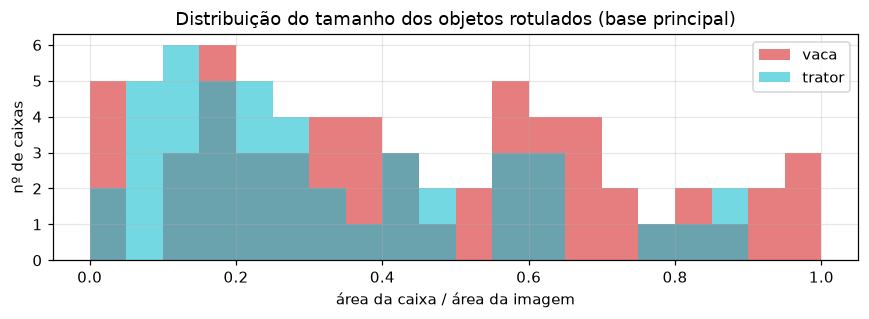

,count,mean,min,50%,max
classe,,,,,
trator,45.0,0.322,0.004,0.248,0.861
vaca,58.0,0.455,0.001,0.414,1.000


In [6]:
# ---- 3.5 Tamanho dos objetos: fração da imagem ocupada por cada caixa ----
areas = [(img.stem.split("_")[0], w * h) for img in sorted(PASTA_BASE.glob("images/*/*.jpg"))
         for _, _, _, w, h in ler_rotulos(img)]                         # (classe, área relativa) de cada caixa
df_areas = pd.DataFrame(areas, columns=["classe", "area"])
fig, ax = plt.subplots(figsize=(8, 3))
for classe, cor in zip(CLASSES, ["tab:red", "tab:cyan"]):
    ax.hist(df_areas.query("classe == @classe").area, bins=np.linspace(0, 1, 21), alpha=0.6, color=cor, label=classe)
ax.set_xlabel("área da caixa / área da imagem"); ax.set_ylabel("nº de caixas"); ax.legend()
ax.set_title("Distribuição do tamanho dos objetos rotulados (base principal)")
plt.tight_layout(); plt.show()
display(df_areas.groupby("classe").area.describe()[["count", "mean", "min", "50%", "max"]])

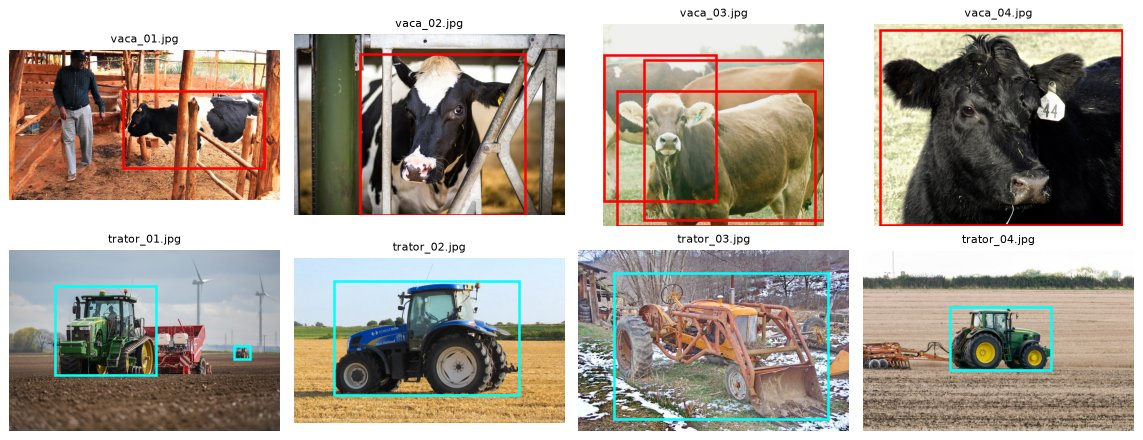

In [7]:
# ---- 3.6 Amostras do conjunto de treino com as caixas rotuladas ----
amostra = sorted(PASTA_BASE.glob("images/train/vaca_*.jpg"))[:4] + sorted(PASTA_BASE.glob("images/train/trator_*.jpg"))[:4]
grade_imagens(amostra, caixas=True, arquivo="amostras_rotuladas.jpg")   # vermelho = vaca, ciano = trator

## 4. Entrega 1 – YOLOv5 customizado

### 4.1 Estratégia

- **Modelo:** YOLOv5s (*small*, 7 milhões de parâmetros) partindo dos pesos pré-treinados no COCO (*transfer learning*). Com apenas 64 imagens de treino, treinar a rede do zero não convergiria; reaproveitar os filtros já aprendidos no COCO é o procedimento recomendado pela própria Ultralytics para bases customizadas.
- **Hiperparâmetros:** os padrões do YOLOv5 (`hyp.scratch-low`: SGD, lr0 = 0,01, *warm-up* de 3 épocas, aumentação *mosaic*, HSV, translação, escala e espelhamento), lote de 16 e imagens de **320 px**. **Só o número de épocas muda entre as simulações**, de modo que a comparação isola o efeito desse parâmetro.
- **Simulação A:** 15 épocas. **Simulação B:** 30 épocas.
- **Por que 320 px e 15 × 30 épocas (e não 640 px e 30 × 60):** esta execução foi feita em CPU, sem GPU disponível, e com o prazo de entrega próximo. Em CPU, uma época a 640 px levava cerca de 1 minuto. Reduzir a resolução pela metade corta o custo por época em cerca de 4×, e 15 × 30 épocas mantém a proporção de 1 para 2 entre as simulações, que é o que o enunciado pede (quantidades bem diferentes). Com GPU (Colab), basta trocar `TAM_IMG = 640` e `SIMULACOES = {"30ep": 30, "60ep": 60}` na célula 4.2.
- **Passo a passo:** (1) **treino** com `train.py` (ao fim de cada época o modelo é avaliado no conjunto de validação e o melhor checkpoint vira `best.pt`); (2) **validação** com `val.py --task val`; (3) **teste** com `val.py --task test` (métricas) e `detect.py` (imagens processadas, salvas em `yolov5/runs/detect/...`).

**Métricas usadas:** *precision* (das caixas previstas, quantas estão certas), *recall* (dos objetos reais, quantos foram encontrados), **mAP@0,5** (área sob a curva precisão × recall, aceitando uma caixa como correta quando o IoU com a caixa real é ≥ 0,5) e **mAP@0,5:0,95** (média do mAP para IoU de 0,5 a 0,95, que mede também a precisão do enquadramento). O **erro** é acompanhado pelas três perdas do YOLO: `box` (localização), `obj` (existência de objeto) e `cls` (classe).

In [8]:
# ---- 4.2 Arquivo de configuração da base (data.yaml) ----
DATA_YAML = PASTA_RESULTADOS / "data.yaml"                             # gerado com o caminho absoluto da base
DATA_YAML.write_text(
    f"path: {PASTA_BASE.as_posix()}\n"                                 # raiz da base (Drive ou pasta local)
    "train: images/train\n"                                            # 64 imagens de treino
    "val: images/val\n"                                                # 8 imagens de validação
    "test: images/test\n"                                              # 8 imagens de teste
    f"nc: {len(CLASSES)}\n"                                            # número de classes
    f"names: {CLASSES}\n")                                             # nomes na ordem dos índices
print(DATA_YAML.read_text())

TAM_IMG = 320                                                          # resolução de entrada do YOLOv5 (ver 4.1)
SIMULACOES = {"15ep": 15, "30ep": 30}                       # nome da simulação -> número de épocas
TREINO = {}                                                            # tempos e caminhos de cada simulação

path: D:/FIAP/fase_6_cap_1/dataset
train: images/train
val: images/val
test: images/test
nc: 2
names: ['vaca', 'trator']



### 4.3 Treinamento – Simulação A (15 épocas)

O comando é o mesmo do capítulo de YOLO, só que chamado a partir do Python para medir o tempo e guardar o log completo em `resultados/logs/`. A saída mostra o resumo final: a validação do `best.pt` e o caminho `Results saved to runs/train/...`.

In [9]:
# ---- Simulação A: 15 épocas ----
def treinar(nome, epocas):
    # Treina o YOLOv5s a partir dos pesos do COCO e registra o tempo total.
    args = ["--img", TAM_IMG, "--batch", 16, "--epochs", epocas, "--data", DATA_YAML, "--weights", "yolov5s.pt",
            "--project", "runs/train", "--name", f"treino_{nome}", "--exist-ok", "--device", DISPOSITIVO,
            "--workers", 2, "--cache", "ram", "--seed", SEMENTE]
    segundos, _ = rodar("train.py", args, f"treino_{nome}", mostrar=8)
    pasta = PASTA_YOLO / "runs" / "train" / f"treino_{nome}"
    TREINO[nome] = dict(epocas=epocas, segundos=segundos, pasta=pasta, best=pasta / "weights" / "best.pt")
    print(f"\n>>> Tempo de treinamento ({epocas} épocas): {segundos / 60:.1f} min ({segundos / epocas:.1f} s/época)")

treinar("15ep", SIMULACOES["15ep"])

Validating runs\train\treino_15ep\weights\best.pt...
Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 1/1 1.1it/s 0.9s
                   all          8         10     0.0957      0.292      0.266      0.114
                  vaca          8          6      0.102      0.333      0.213      0.111
                trator          8          4     0.0898       0.25      0.319      0.118
Results saved to runs\train\treino_15ep

>>> Tempo de treinamento (15 épocas): 5.0 min (20.1 s/época)


### 4.4 Treinamento – Simulação B (30 épocas)

Mesmos dados, mesmos hiperparâmetros e mesma semente; só o número de épocas dobra.

In [10]:
# ---- Simulação B: 30 épocas ----
treinar("30ep", SIMULACOES["30ep"])

Validating runs\train\treino_30ep\weights\best.pt...
Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 1/1 1.3it/s 0.8s
                   all          8         10      0.891      0.852      0.926      0.472
                  vaca          8          6      0.782          1      0.995      0.516
                trator          8          4          1      0.704      0.856      0.428
Results saved to runs\train\treino_30ep

>>> Tempo de treinamento (30 épocas): 13.5 min (27.0 s/época)


### 4.5 Curvas de aprendizado

O `train.py` grava em `results.csv` as perdas de treino e de validação e as métricas de validação de **cada época**. Comparar as curvas das duas simulações mostra quanto o modelo ainda melhora depois da 15ª época e se há sinal de sobreajuste (perda de validação subindo enquanto a de treino cai).

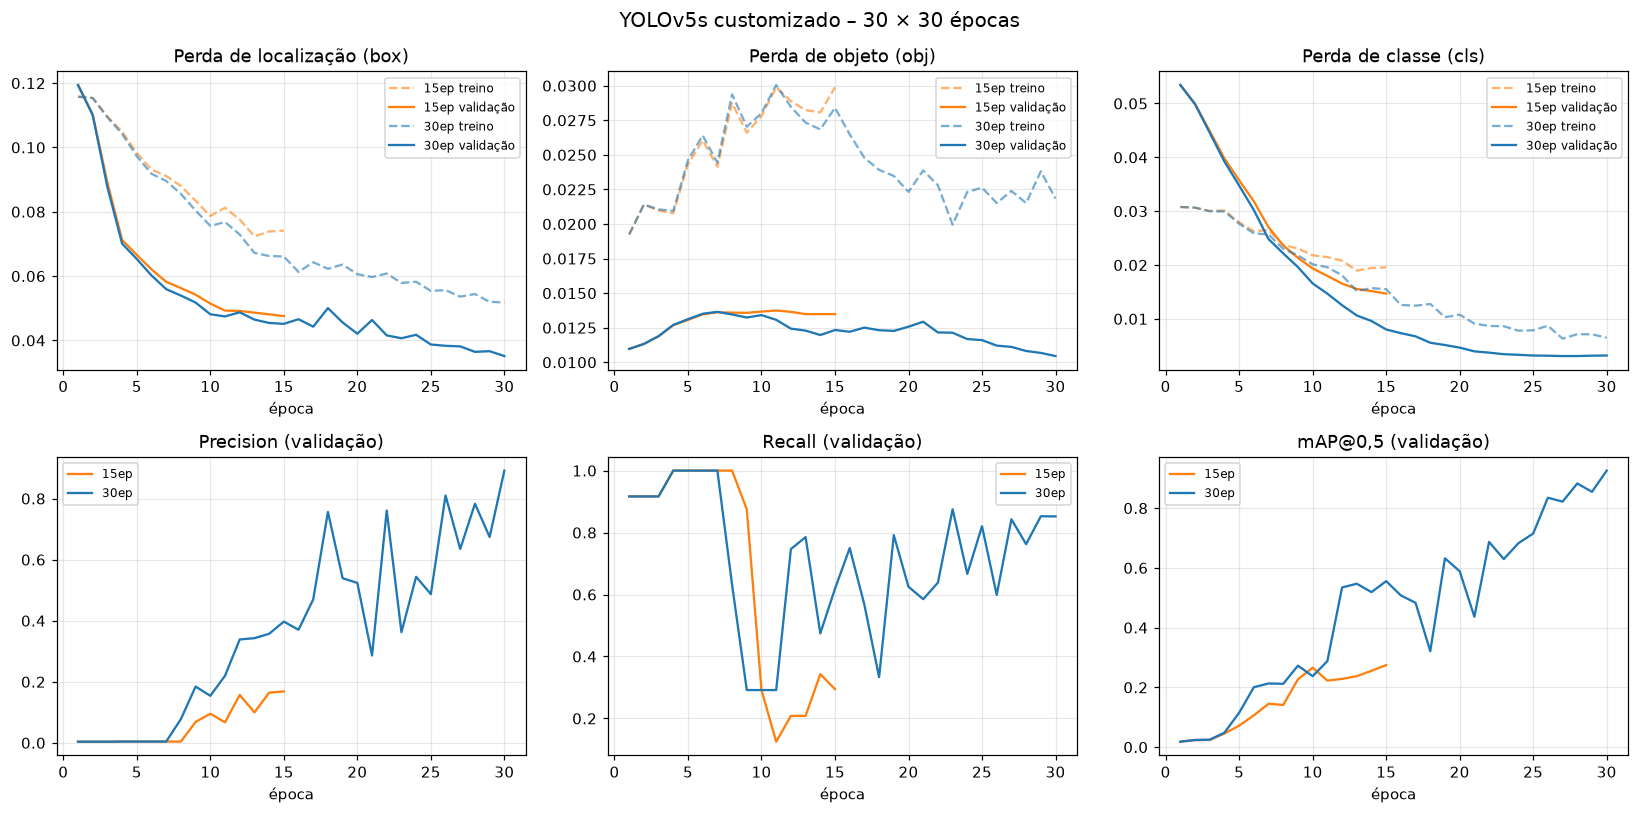

,melhor época,mAP50 (melhor),mAP50-95 (melhor),perda val. total (última),perda treino total (última)
simulação,,,,,
15ep,10,0.266,0.114,0.076,0.124
30ep,30,0.926,0.472,0.049,0.080


In [11]:
# ---- 4.5 Curvas: perdas (erro) e métricas de validação por época ----
hist = {nome: pd.read_csv(t["pasta"] / "results.csv").rename(columns=lambda c: c.strip())
        for nome, t in TREINO.items()}                                 # uma tabela por simulação (colunas sem espaços)
paineis = [("box_loss", "Perda de localização (box)"), ("obj_loss", "Perda de objeto (obj)"),
           ("cls_loss", "Perda de classe (cls)"), ("metrics/precision", "Precision (validação)"),
           ("metrics/recall", "Recall (validação)"), ("metrics/mAP_0.5", "mAP@0,5 (validação)")]
fig, eixos = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, (col, titulo) in zip(eixos.ravel(), paineis):
    for (nome, h), cor in zip(hist.items(), ["tab:orange", "tab:blue"]):
        if col.endswith("loss"):                                       # perdas: treino (tracejado) e validação (contínua)
            ax.plot(h.epoch + 1, h[f"train/{col}"], "--", color=cor, alpha=0.6, label=f"{nome} treino")
            ax.plot(h.epoch + 1, h[f"val/{col}"], color=cor, label=f"{nome} validação")
        else:
            ax.plot(h.epoch + 1, h[col], color=cor, label=nome)
    ax.set_title(titulo); ax.set_xlabel("época"); ax.legend(fontsize=8)
plt.suptitle("YOLOv5s customizado – 30 × 30 épocas", fontsize=13)
plt.tight_layout(); plt.savefig(PASTA_FIGURAS / "curvas_treino_15x30.png", bbox_inches="tight"); plt.show()

# Resumo numérico: melhor época (critério de fitness do YOLOv5) e valores na última época
resumo_treino = []
for nome, h in hist.items():
    fit = 0.1 * h["metrics/mAP_0.5"] + 0.9 * h["metrics/mAP_0.5:0.95"]  # mesma fórmula usada para escolher o best.pt
    b, u = h.loc[fit.idxmax()], h.iloc[-1]
    resumo_treino.append({"simulação": nome, "melhor época": int(b.epoch) + 1,
                          "mAP50 (melhor)": b["metrics/mAP_0.5"], "mAP50-95 (melhor)": b["metrics/mAP_0.5:0.95"],
                          "perda val. total (última)": u[["val/box_loss", "val/obj_loss", "val/cls_loss"]].sum(),
                          "perda treino total (última)": u[["train/box_loss", "train/obj_loss", "train/cls_loss"]].sum()})
display(pd.DataFrame(resumo_treino).set_index("simulação"))

### 4.6 Validação

O `val.py` reavalia o `best.pt` de cada simulação no conjunto de **validação** (8 imagens), com a tabela por classe e a matriz de confusão.

In [12]:
# ---- 4.6 Validação dos dois modelos ----
VAL = {}
for nome, t in TREINO.items():
    print(f"=============== Validação – {nome} ===============")
    _, linhas = rodar("val.py", ["--weights", t["best"], "--data", DATA_YAML, "--img", TAM_IMG, "--task", "val",
                                 "--project", "runs/val", "--name", f"val_{nome}", "--exist-ok",
                                 "--device", DISPOSITIVO, "--verbose"], f"val_{nome}", mostrar=6)
    VAL[nome] = ler_metricas(linhas)
tab_val = pd.concat({n: m for n, (m, _) in VAL.items()}, names=["simulação", "classe"])
display(tab_val)

=============== Validação – 15ep ===============


                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 1/1 21.6s/it 21.6s
                   all          8         10     0.0955      0.292      0.266      0.114
                  vaca          8          6      0.101      0.333      0.213      0.111
                trator          8          4     0.0897       0.25      0.319      0.118
Speed: 6.2ms pre-process, 405.3ms inference, 47.0ms NMS per image at shape (32, 3, 320, 320)
Results saved to runs\val\val_15ep
=============== Validação – 30ep ===============


                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 1/1 20.5s/it 20.5s
                   all          8         10      0.891      0.852      0.926      0.472
                  vaca          8          6      0.783          1      0.995      0.516
                trator          8          4          1      0.704      0.856      0.428
Speed: 4.7ms pre-process, 189.4ms inference, 10.8ms NMS per image at shape (32, 3, 320, 320)
Results saved to runs\val\val_30ep


imagens  instancias      P      R  mAP50  mAP50_95
simulação classe                                                    
15ep      all         8.0        10.0  0.096  0.292  0.266     0.114
          vaca        8.0         6.0  0.101  0.333  0.213     0.111
          trator      8.0         4.0  0.090  0.250  0.319     0.118
30ep      all         8.0        10.0  0.891  0.852  0.926     0.472
          vaca        8.0         6.0  0.783  1.000  0.995     0.516
          trator      8.0         4.0  1.000  0.704  0.856     0.428

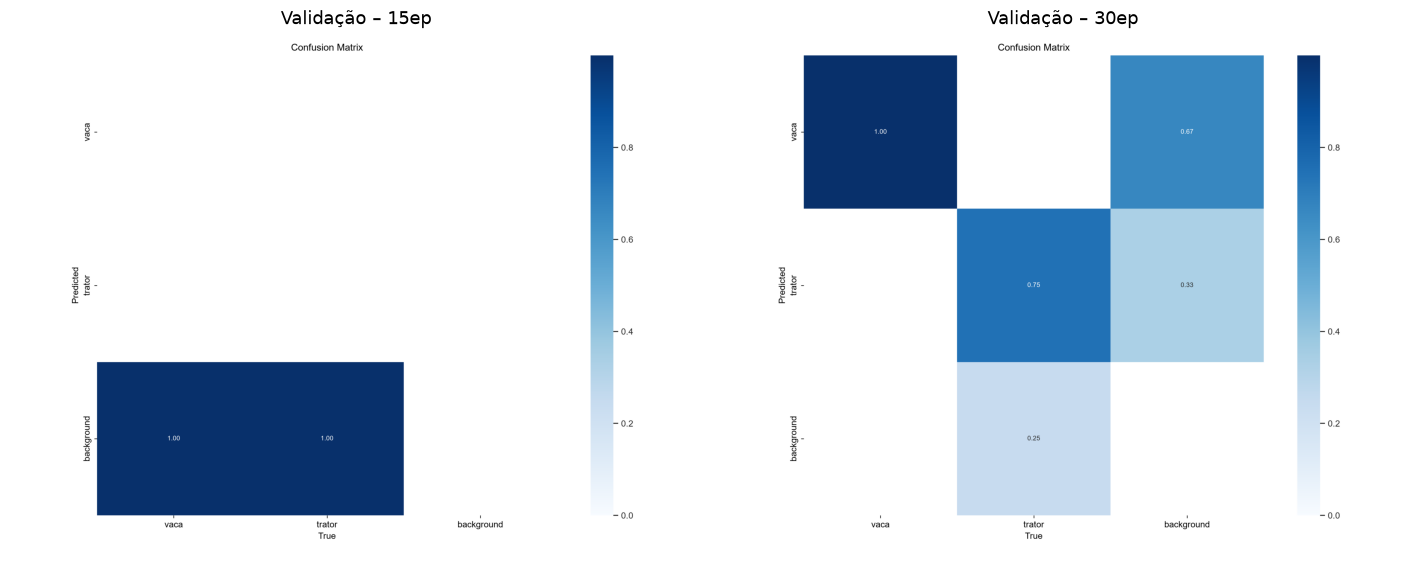

In [13]:
# ---- Matrizes de confusão da validação (geradas pelo val.py) ----
fig, eixos = plt.subplots(1, len(TREINO), figsize=(13, 5.5))
for ax, nome in zip(np.atleast_1d(eixos), TREINO):
    ax.imshow(Image.open(PASTA_YOLO / "runs" / "val" / f"val_{nome}" / "confusion_matrix.png"))
    ax.set_title(f"Validação – {nome}"); ax.axis("off")
plt.tight_layout(); plt.show()

### 4.7 Teste

Agora com as 8 imagens de **teste**, que não participaram nem do treino nem da escolha do `best.pt`. Primeiro as métricas (`val.py --task test`); depois o `detect.py`, que desenha as detecções e grava as imagens em `yolov5/runs/detect/<nome>` (o enunciado se refere a essas pastas como `expX`; aqui elas recebem nomes descritivos para não depender da ordem de execução).

In [14]:
# ---- 4.7 Métricas no conjunto de teste ----
TESTE = {}
for nome, t in TREINO.items():
    print(f"=============== Teste – {nome} ===============")
    _, linhas = rodar("val.py", ["--weights", t["best"], "--data", DATA_YAML, "--img", TAM_IMG, "--task", "test",
                                 "--project", "runs/val", "--name", f"teste_{nome}", "--exist-ok",
                                 "--device", DISPOSITIVO, "--verbose"], f"teste_{nome}", mostrar=6)
    TESTE[nome] = ler_metricas(linhas)
tab_teste = pd.concat({n: m for n, (m, _) in TESTE.items()}, names=["simulação", "classe"])
display(tab_teste)

=============== Teste – 15ep ===============


                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 1/1 27.2s/it 27.2s
                   all          8         10      0.012          1      0.116     0.0386
                  vaca          8          5     0.0138          1     0.0996     0.0454
                trator          8          5     0.0102          1      0.133     0.0318
Speed: 5.9ms pre-process, 508.2ms inference, 75.5ms NMS per image at shape (32, 3, 320, 320)
Results saved to runs\val\teste_15ep
=============== Teste – 30ep ===============


                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 1/1 27.4s/it 27.4s
                   all          8         10      0.766        0.9       0.95      0.554
                  vaca          8          5      0.754          1      0.962      0.709
                trator          8          5      0.778        0.8      0.938        0.4
Speed: 33.6ms pre-process, 449.2ms inference, 11.6ms NMS per image at shape (32, 3, 320, 320)
Results saved to runs\val\teste_30ep


imagens  instancias      P    R  mAP50  mAP50_95
simulação classe                                                  
15ep      all         8.0        10.0  0.012  1.0  0.116     0.039
          vaca        8.0         5.0  0.014  1.0  0.100     0.045
          trator      8.0         5.0  0.010  1.0  0.133     0.032
30ep      all         8.0        10.0  0.766  0.9  0.950     0.554
          vaca        8.0         5.0  0.754  1.0  0.962     0.709
          trator      8.0         5.0  0.778  0.8  0.938     0.400

In [15]:
# ---- Detecção nas imagens de teste (prints para o cliente) ----
for nome, t in TREINO.items():
    print(f"=============== detect.py – {nome} ===============")
    rodar("detect.py", ["--weights", t["best"], "--source", PASTA_BASE / "images" / "test", "--img", TAM_IMG,
                        "--conf-thres", 0.25, "--project", "runs/detect", "--name", f"teste_{nome}", "--exist-ok",
                        "--device", DISPOSITIVO, "--line-thickness", 3], f"detect_{nome}", mostrar=2)

=============== detect.py – 15ep ===============


Speed: 0.6ms pre-process, 86.6ms inference, 0.2ms NMS per image at shape (1, 3, 320, 320)
Results saved to runs\detect\teste_15ep
=============== detect.py – 30ep ===============


Speed: 0.5ms pre-process, 112.9ms inference, 1.1ms NMS per image at shape (1, 3, 320, 320)
Results saved to runs\detect\teste_30ep


Modelo de 15ep – 8 imagens de teste processadas


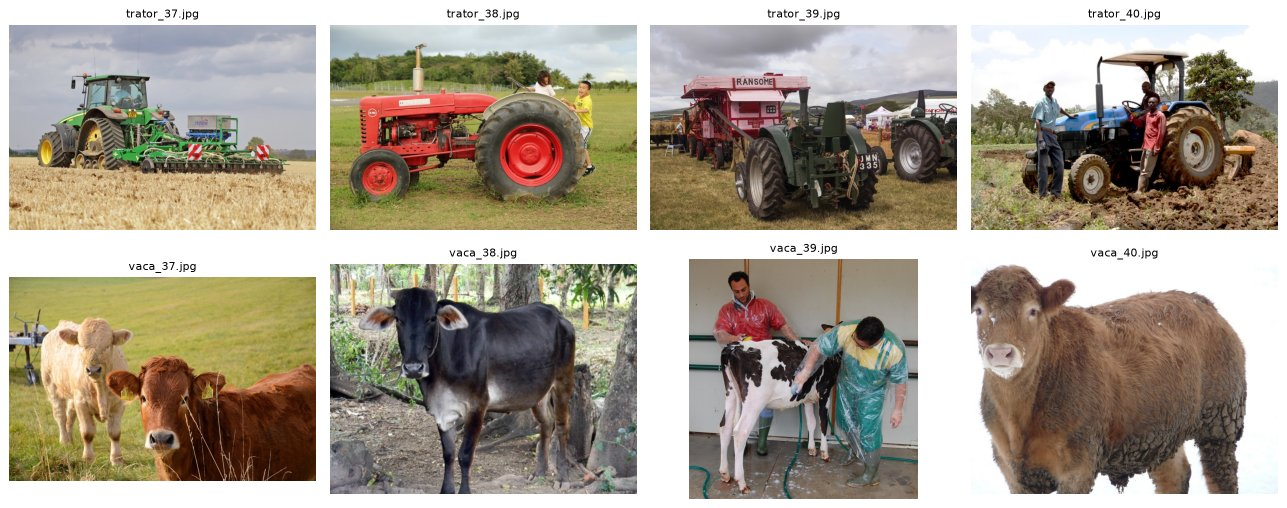

Modelo de 30ep – 8 imagens de teste processadas


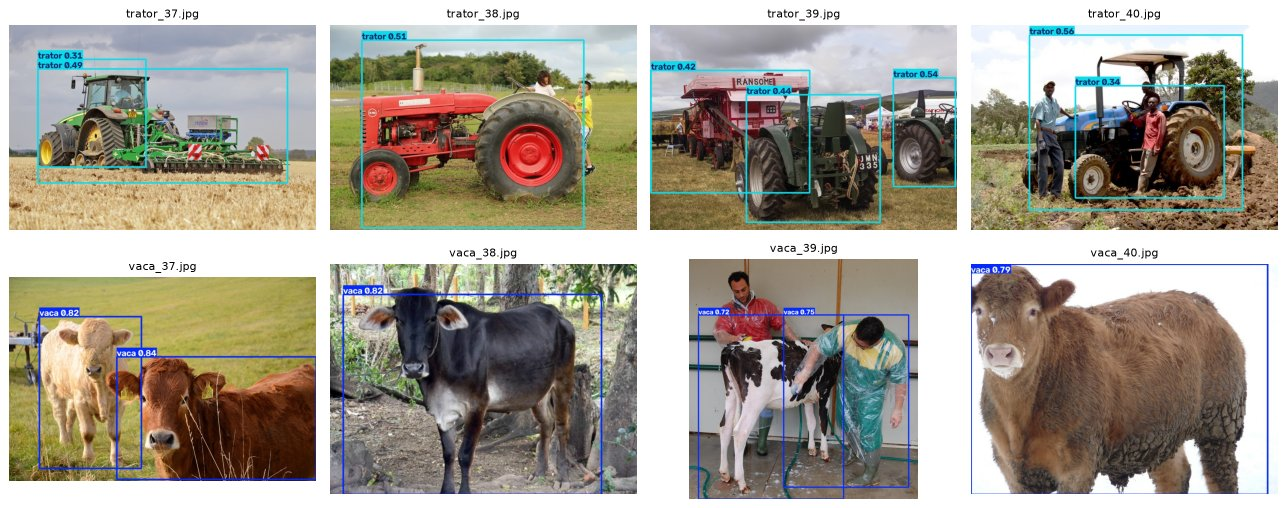

In [16]:
# ---- Imagens de teste processadas pelos dois modelos ----
for nome in TREINO:
    saidas = sorted((PASTA_YOLO / "runs" / "detect" / f"teste_{nome}").glob("*.jpg"))
    print(f"Modelo de {nome} – {len(saidas)} imagens de teste processadas")
    grade_imagens(saidas, colunas=4, tam=3.6, arquivo=f"teste_deteccoes_{nome}.jpg")

### 4.8 Comparação das simulações: acurácia, erro e desempenho

In [17]:
# ---- 4.8 Quadro comparativo 30 × 30 épocas ----
comp = []
for nome, t in TREINO.items():
    mv, msv = VAL[nome]; mt, mst = TESTE[nome]                         # métricas e ms/imagem de validação e teste
    r = next(x for x in resumo_treino if x["simulação"] == nome)
    comp.append({"simulação": nome, "épocas": t["epocas"],
                 "tempo de treino (min)": t["segundos"] / 60, "s/época": t["segundos"] / t["epocas"],
                 "melhor época": r["melhor época"],
                 "val P": mv.loc["all", "P"], "val R": mv.loc["all", "R"],
                 "val mAP50": mv.loc["all", "mAP50"], "val mAP50-95": mv.loc["all", "mAP50_95"],
                 "teste P": mt.loc["all", "P"], "teste R": mt.loc["all", "R"],
                 "teste mAP50": mt.loc["all", "mAP50"], "teste mAP50-95": mt.loc["all", "mAP50_95"],
                 "perda val. final": r["perda val. total (última)"],
                 "inferência (ms/img)": mst})   # média do val.py no teste (lote de 32)
tab_comp = pd.DataFrame(comp).set_index("simulação")
display(formatar(tab_comp, {"épocas": "{:.0f}", "tempo de treino (min)": "{:.1f}", "s/época": "{:.1f}",
                            "melhor época": "{:.0f}", "inferência (ms/img)": "{:.0f}"}).T)

# Modelo escolhido para a Entrega 2: maior mAP50-95 na validação (desempate: menor tempo de treino)
ESCOLHIDO = max(TREINO, key=lambda n: (VAL[n][0].loc["all", "mAP50_95"], -TREINO[n]["segundos"]))
print(f"Modelo customizado escolhido para a Entrega 2: {ESCOLHIDO} ({TREINO[ESCOLHIDO]['best']})")

simulação,15ep,30ep
épocas,15,30
tempo de treino (min),5.0,13.5
s/época,20.1,27.0
melhor época,10,30
val P,0.096,0.891
val R,0.292,0.852
val mAP50,0.266,0.926
val mAP50-95,0.114,0.472
teste P,0.012,0.766
teste R,1.000,0.900


Modelo customizado escolhido para a Entrega 2: 30ep (D:\FIAP\fase_6_cap_1\yolov5\runs\train\treino_30ep\weights\best.pt)


### 4.9 Conclusões da Entrega 1

**Acurácia.** Dobrar o número de épocas mudou o modelo de patamar. Com 15 épocas, a YOLO ainda está saindo do *warm-up*: mAP@0,5 de **0,27 na validação e 0,12 no teste**, e precision de 0,01 no teste. O recall de 1,0 nesse caso engana, porque o modelo espalha muitas caixas de baixa confiança e algumas acabam acertando os objetos. Com 30 épocas, o mesmo modelo chega a **mAP@0,5 de 0,93 na validação e 0,95 no teste** (mAP@0,5:0,95 de 0,47 e 0,55), com precision de 0,77 e recall de 0,90 no teste.

**Erro.** As três perdas (box, obj e cls) continuam caindo até a última época nas duas simulações. A perda total de validação termina em 0,076 com 15 épocas e em 0,049 com 30. O melhor checkpoint da simulação de 30 épocas é justamente a última época, e a perda de validação não volta a subir. Ou seja, **não há sinal de sobreajuste**: o modelo ainda tinha espaço para melhorar, e 60 épocas (ou 640 px) provavelmente trariam ganho no mAP@0,5:0,95, que mede o enquadramento fino das caixas.

**Desempenho.** O treino levou 5,0 min (15 épocas) contra 13,5 min (30 épocas) em CPU, de 20 a 27 s por época. O tempo de inferência não depende das épocas, porque a arquitetura é a mesma: as diferenças medidas pelo `val.py` (590 × 494 ms por imagem, em lote, na CPU) são variação de carga da máquina.

**Conclusão da Entrega 1:** com só 64 imagens de treino, o *transfer learning* a partir do COCO faz a YOLOv5s aprender as duas classes em poucos minutos, mas precisa de épocas suficientes para sair do *warm-up* e firmar a confiança das caixas. Entre as duas simulações, **a de 30 épocas é claramente superior** e foi a escolhida para a Entrega 2. A localização da classe **trator** é a mais difícil (mAP@0,5:0,95 de 0,40 contra 0,71 da vaca), porque tratores aparecem com implementos e reboques acoplados e a fronteira da caixa é menos óbvia.

## 5. Entrega 2 – Comparação com abordagens "concorrentes"

Três abordagens, avaliadas com o **mesmo protocolo**:

| Abordagem | O que é | Saída |
|---|---|---|
| **YOLO customizado** (Entrega 1) | YOLOv5s com pesos do COCO, ajustado (*fine-tuning*) às nossas 64 imagens | caixas + classe `vaca`/`trator` |
| **YOLO padrão** | o mesmo YOLOv5s **sem customização**, com os pesos originais do COCO (80 classes), como visto no capítulo de YOLO | caixas + uma das 80 classes do COCO |
| **CNN treinada do zero** | rede convolucional pequena, pesos aleatórios, treinada só com as 64 imagens de treino | classe da imagem inteira |

**Protocolo de avaliação**

- **Conjuntos:** o teste do enunciado (8 imagens) e o **teste extra** (40 imagens nunca vistas por nenhum modelo). As conclusões se apoiam principalmente nas 48 imagens juntas.
- **Classificação da imagem (as três abordagens):** para os detectores, a classe da imagem é a da detecção mais confiante (confiança ≥ 0,25); sem detecção, a resposta é "nenhum" e conta como erro. Para a CNN, a classe é a de maior probabilidade.
- **Detecção (só os YOLOs):** precision e recall com confiança ≥ 0,25 e AP@0,5 por classe, calculados pela mesma função para os dois detectores.
- **Mapeamento do YOLO padrão:** o COCO tem `cow`, mas **não tem trator**. Avaliamos dois cenários: **estrito** (`cow` → vaca; nada vira trator) e **otimista** (`cow` → vaca e `truck` → trator, a classe em que o COCO costuma "encaixar" um trator).
- **Tempo de inferência:** latência por imagem (lote de 1, já carregada na memória), média de 48 imagens após aquecimento, no mesmo hardware, incluindo pré-processamento e pós-processamento (NMS).

In [18]:
# ---- 5.1 Conjuntos de avaliação e funções de métrica ----
def listar(pasta_base):
    return sorted((pasta_base / "images" / "test").glob("*.jpg"))      # imagens de teste de uma base

AVAL = {"teste (8)": listar(PASTA_BASE), "teste extra (40)": listar(PASTA_EXTRA)}
TODAS = AVAL["teste (8)"] + AVAL["teste extra (40)"]                   # 48 imagens de avaliação
classe_real = lambda p: Path(p).stem.split("_")[0]                     # classe verdadeira pelo nome do arquivo

def caixas_reais(p):
    # Caixas reais em (classe, x1, y1, x2, y2) normalizados.
    return [(CLASSES[c], xc - w / 2, yc - h / 2, xc + w / 2, yc + h / 2) for c, xc, yc, w, h in ler_rotulos(p)]

def iou(a, b):
    # Intersecção sobre união de duas caixas (x1, y1, x2, y2).
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter + 1e-9)

def avaliar_deteccao(preds, imagens, conf_op=0.25):
    # preds: {imagem: [(classe, conf, x1, y1, x2, y2), ...]}. Retorna P, R (conf >= conf_op) e AP@0,5 por classe.
    trapz = getattr(np, "trapezoid", None) or np.trapz
    linhas = []
    for c in CLASSES:
        gts = {p: [g[1:] for g in caixas_reais(p) if g[0] == c] for p in imagens}
        n_gt = sum(map(len, gts.values()))
        dets = sorted([(d[1], p, d[2:]) for p in imagens for d in preds[p] if d[0] == c], key=lambda x: -x[0])
        usados = {p: [False] * len(gts[p]) for p in imagens}
        tp = []
        for conf, p, cx in dets:                                       # casamento guloso por confiança decrescente
            ious = [iou(cx, g) for g in gts[p]]
            j = int(np.argmax(ious)) if ious else -1
            ok = j >= 0 and ious[j] >= 0.5 and not usados[p][j]
            if ok:
                usados[p][j] = True
            tp.append(ok)
        tp = np.array(tp, dtype=bool); confs = np.array([d[0] for d in dets])
        acum_tp = np.cumsum(tp); acum_fp = np.cumsum(~tp)
        rec = acum_tp / max(n_gt, 1); prec = acum_tp / np.maximum(acum_tp + acum_fp, 1)
        mrec = np.concatenate(([0.0], rec, [1.0])); mpre = np.concatenate(([1.0], prec, [0.0]))
        mpre = np.flip(np.maximum.accumulate(np.flip(mpre)))           # envelope da curva precisão × recall
        x = np.linspace(0, 1, 101)
        ap = trapz(np.interp(x, mrec, mpre), x) if len(dets) else 0.0  # AP interpolado em 101 pontos (como no YOLOv5)
        sel = confs >= conf_op
        linhas.append(dict(classe=c, objetos=n_gt, P=tp[sel].mean() if sel.any() else 0.0,
                           R=tp[sel].sum() / max(n_gt, 1), AP50=ap))
    df = pd.DataFrame(linhas).set_index("classe")
    df.loc["média"] = [df.objetos.sum(), df.P.mean(), df.R.mean(), df.AP50.mean()]
    return df

def classificar_por_deteccao(preds, conf_op=0.25):
    # Classe da imagem = classe da detecção mais confiante (ou "nenhum").
    out = {}
    for p, ds in preds.items():
        ds = [d for d in ds if d[1] >= conf_op]
        out[p] = max(ds, key=lambda d: d[1])[0] if ds else "nenhum"
    return out

def acuracia(pred_cls, imagens):
    return np.mean([pred_cls[p] == classe_real(p) for p in imagens])   # fração de imagens com a classe correta

RESULTADOS = []                                                        # linhas do quadro comparativo final
print({k: len(v) for k, v in AVAL.items()})

{'teste (8)': 8, 'teste extra (40)': 40}


In [19]:
# ---- 5.2 Carregando os dois detectores pela API do YOLOv5 (torch.hub, código local) ----
def carregar_yolo(pesos):
    m = torch.hub.load(str(PASTA_YOLO), "custom", path=str(pesos), source="local", _verbose=False)
    m.conf, m.iou, m.max_det = 0.001, 0.45, 100                        # limiar baixo: permite calcular a curva P×R (AP)
    return m.to("cuda" if DISPOSITIVO == "0" else "cpu").eval()

yolo_custom = carregar_yolo(TREINO[ESCOLHIDO]["best"])                 # YOLO customizado (Entrega 1)
yolo_coco = carregar_yolo(PASTA_YOLO / "yolov5s.pt")                   # YOLO padrão: pesos originais do COCO
print("Classes do customizado:", yolo_custom.names)
print("YOLO padrão:", len(yolo_coco.names), "classes do COCO; tem trator?", any("tractor" in n for n in yolo_coco.names.values()))

def predizer_yolo(modelo, imagens, mapa=None):
    # Detecções em (classe, conf, x1, y1, x2, y2) normalizados; 'mapa' traduz classes do COCO para as nossas.
    preds = {}
    for p in imagens:                                                  # uma imagem por vez (limite de tempo do NMS é por lote)
        det = modelo(str(p), size=TAM_IMG).xyxyn[0]
        lista = []
        for x1, y1, x2, y2, conf, k in det.tolist():
            nome = modelo.names[int(k)]
            nome = mapa.get(nome) if mapa is not None else nome          # classe fora do mapa vira None
            lista.append((nome, conf, x1, y1, x2, y2))
        preds[p] = lista
    return preds

Classes do customizado: {0: 'vaca', 1: 'trator'}
YOLO padrão: 80 classes do COCO; tem trator? False


### 5.3 YOLO padrão (COCO, sem customização)

Antes das métricas, o que o YOLO padrão "enxerga" nas imagens de teste: o `detect.py` com os pesos originais grava as imagens em `yolov5/runs/detect/teste_yolo_padrao`.

Speed: 5.5ms pre-process, 224.9ms inference, 2.1ms NMS per image at shape (1, 3, 320, 320)
Results saved to runs\detect\teste_yolo_padrao


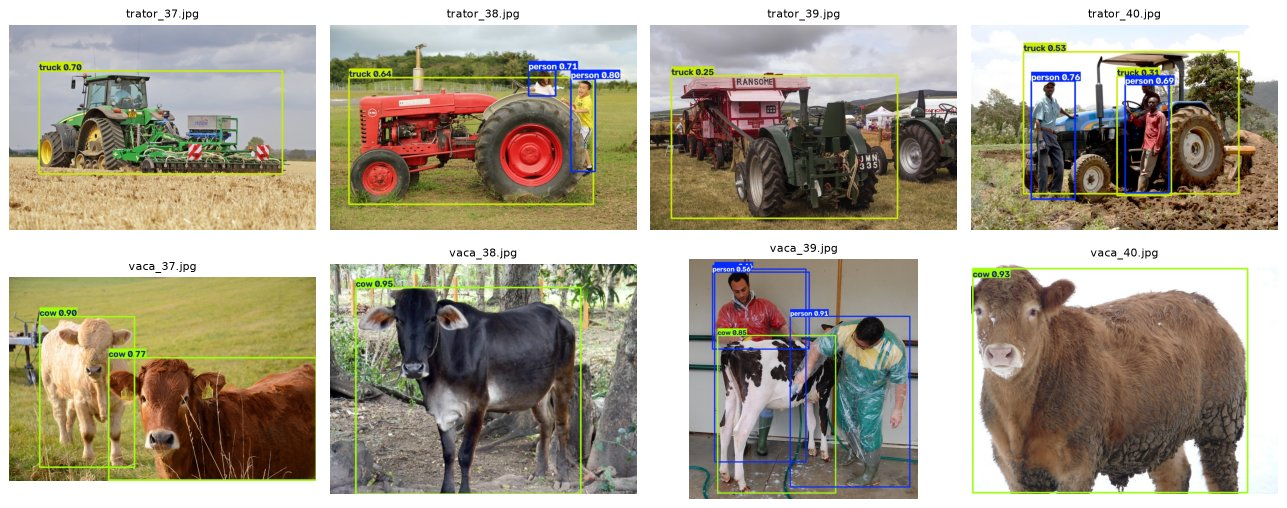

In [20]:
# ---- 5.3 YOLO padrão: detecções desenhadas nas 8 imagens de teste ----
rodar("detect.py", ["--weights", "yolov5s.pt", "--source", PASTA_BASE / "images" / "test", "--img", TAM_IMG,
                    "--conf-thres", 0.25, "--project", "runs/detect", "--name", "teste_yolo_padrao", "--exist-ok",
                    "--device", DISPOSITIVO, "--line-thickness", 3], "detect_yolo_padrao", mostrar=2)
grade_imagens(sorted((PASTA_YOLO / "runs" / "detect" / "teste_yolo_padrao").glob("*.jpg")), colunas=4, tam=3.6,
              arquivo="teste_deteccoes_yolo_padrao.jpg")

In [21]:
# ---- O que o YOLO padrão responde para cada classe real (classe COCO mais confiante, 48 imagens) ----
preds_coco_bruto = predizer_yolo(yolo_coco, TODAS)                     # classes originais do COCO
top_coco = classificar_por_deteccao(preds_coco_bruto)
dist = pd.crosstab(pd.Series([classe_real(p) for p in TODAS], name="classe real"),
                   pd.Series([top_coco[p] for p in TODAS], name="classe COCO mais confiante"))
display(dist)

classe COCO mais confiante,cow,elephant,motorcycle,person,train,truck
classe real,,,,,,
trator,0,1,1,9,1,12
vaca,21,0,0,3,0,0


In [22]:
# ---- Métricas do YOLO padrão nos dois cenários de mapeamento ----
MAPAS = {"YOLO padrão (estrito)": {"cow": "vaca"},
         "YOLO padrão (otimista)": {"cow": "vaca", "truck": "trator"}}
PRED_DET = {}                                                          # guarda as predições de cada detector
for nome, mapa in MAPAS.items():
    preds = {p: [d for d in ds if d[0] is not None] for p, ds in predizer_yolo(yolo_coco, TODAS, mapa).items()}
    PRED_DET[nome] = preds
    print(f"=== {nome} ===")
    display(pd.concat({k: avaliar_deteccao(preds, ims) for k, ims in AVAL.items()}, axis=1))

=== YOLO padrão (estrito) ===


teste (8)                  teste extra (40)                     
         objetos    P    R   AP50          objetos      P      R   AP50
classe                                                                 
vaca         5.0  1.0  1.0  0.995             26.0  0.828  0.923  0.982
trator       5.0  0.0  0.0  0.000             22.0  0.000  0.000  0.000
média       10.0  0.5  0.5  0.497             48.0  0.414  0.462  0.491

=== YOLO padrão (otimista) ===


teste (8)                  teste extra (40)                     
         objetos    P    R   AP50          objetos      P      R   AP50
classe                                                                 
vaca         5.0  1.0  1.0  0.995             26.0  0.828  0.923  0.982
trator       5.0  0.6  0.6  0.561             22.0  0.720  0.818  0.782
média       10.0  0.8  0.8  0.778             48.0  0.774  0.871  0.882

### 5.4 YOLO customizado no mesmo protocolo

teste (8)                    teste extra (40)                     
         objetos      P    R   AP50          objetos      P      R   AP50
classe                                                                   
vaca         5.0  0.833  1.0  0.962             26.0  0.774  0.923  0.915
trator       5.0  0.625  1.0  0.880             22.0  0.564  1.000  0.820
média       10.0  0.729  1.0  0.921             48.0  0.669  0.962  0.867

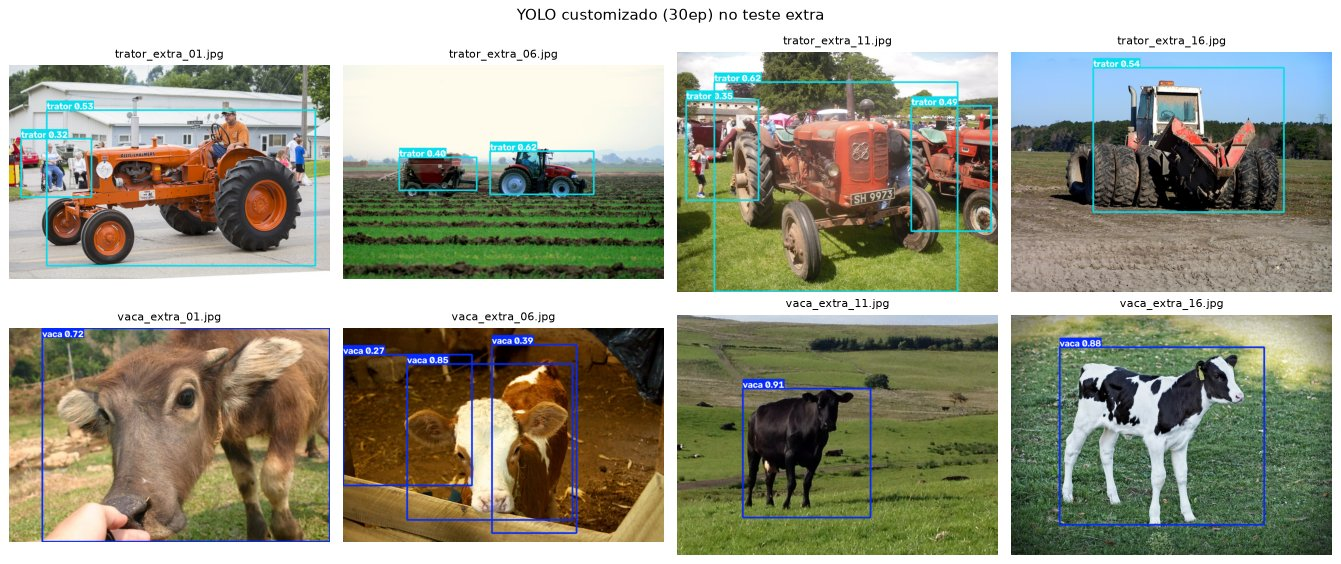

In [23]:
# ---- 5.4 YOLO customizado: mesmas imagens, mesma função de métrica ----
PRED_DET["YOLO customizado"] = predizer_yolo(yolo_custom, TODAS)
display(pd.concat({k: avaliar_deteccao(PRED_DET["YOLO customizado"], ims) for k, ims in AVAL.items()}, axis=1))

# Imagens do teste extra processadas pelo customizado (amostra de 8)
amostra_extra = AVAL["teste extra (40)"][::5]
yolo_custom.conf = 0.25                                                # limiar de uso para desenhar
desenhos = yolo_custom([str(p) for p in amostra_extra], size=TAM_IMG).render()  # desenha as caixas nas imagens
yolo_custom.conf = 0.001
fig, eixos = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, im, p in zip(eixos.ravel(), desenhos, amostra_extra):
    ax.imshow(im); ax.set_title(p.name, fontsize=9); ax.axis("off")
plt.suptitle(f"YOLO customizado ({ESCOLHIDO}) no teste extra"); plt.tight_layout()
mostrar_jpeg(fig, "teste_extra_yolo_customizado.jpg")

### 5.5 CNN treinada do zero

Uma CNN pequena, no estilo das vistas no capítulo de redes convolucionais, com **pesos inicializados aleatoriamente** (nenhum pré-treino). Como a base é minúscula (64 imagens), três cuidados contra sobreajuste:

- **aumentação de dados** dentro do modelo (espelhamento, rotação, zoom, translação e contraste aleatórios, ativos apenas no treino);
- **BatchNormalization e Dropout**, e *Global Average Pooling* em vez de camadas densas grandes (menos parâmetros);
- **parada antecipada** pela perda de validação, restaurando os melhores pesos.

A tarefa é diferente da do YOLO: a CNN **não localiza** objetos, apenas diz se a imagem é de `vaca` ou de `trator`. Para treiná-la, basta o rótulo da imagem (o nome do arquivo); as caixas do Make Sense não são usadas.

In [24]:
# ---- 5.5.1 Dados para a CNN: imagens redimensionadas para 160×160 ----
import tensorflow as tf                                                # TensorFlow/Keras para a CNN
tf.get_logger().setLevel("ERROR")                                      # oculta avisos do TensorFlow
from tensorflow import keras
from tensorflow.keras import layers
keras.utils.disable_interactive_logging()                              # sem barras de progresso do Keras
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)                # TensorFlow não reserva a GPU inteira (o PyTorch também a usa)

TAM_CNN = 160                                                          # resolução de entrada da CNN
def carregar_classificacao(imagens):
    X = np.stack([np.asarray(Image.open(p).convert("RGB").resize((TAM_CNN, TAM_CNN)), dtype=np.float32) for p in imagens])
    y = np.array([CLASSES.index(classe_real(p)) for p in imagens], dtype=np.float32)   # 0 = vaca, 1 = trator
    return X, y

ims_treino = sorted((PASTA_BASE / "images" / "train").glob("*.jpg"))
ims_val = sorted((PASTA_BASE / "images" / "val").glob("*.jpg"))
X_tr, y_tr = carregar_classificacao(ims_treino)
X_va, y_va = carregar_classificacao(ims_val)
print(f"TensorFlow {tf.__version__} | treino {X_tr.shape} | validação {X_va.shape} | proporção de tratores no treino: {y_tr.mean():.2f}")

TensorFlow 2.21.0 | treino (64, 160, 160, 3) | validação (8, 160, 160, 3) | proporção de tratores no treino: 0.50


In [25]:
# ---- 5.5.2 Arquitetura da CNN ----
keras.utils.set_random_seed(SEMENTE)                                   # pesos iniciais e aumentação reprodutíveis

def criar_cnn():
    def bloco(x, filtros):                                             # convolução 3×3 + normalização + ReLU + pooling
        x = layers.Conv2D(filtros, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        return layers.MaxPooling2D()(x)
    entrada = keras.Input((TAM_CNN, TAM_CNN, 3))
    x = layers.RandomFlip("horizontal")(entrada)                       # aumentação (só no treino)
    x = layers.RandomRotation(0.08)(x)
    x = layers.RandomZoom(0.2)(x)
    x = layers.RandomTranslation(0.1, 0.1)(x)
    x = layers.RandomContrast(0.2)(x)
    x = layers.Rescaling(1 / 255)(x)                                   # pixels de 0-255 para 0-1
    for filtros in (32, 64, 128, 256):                                 # 4 blocos: 160 → 80 → 40 → 20 → 10 px
        x = bloco(x, filtros)
    x = layers.GlobalAveragePooling2D()(x)                             # um valor por mapa de características
    x = layers.Dropout(0.4)(x)
    saida = layers.Dense(1, activation="sigmoid")(x)                   # probabilidade de ser trator
    modelo = keras.Model(entrada, saida, name="cnn_do_zero")
    modelo.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])
    return modelo

cnn = criar_cnn()
camadas = pd.DataFrame([(c.name, c.__class__.__name__, str(tuple(c.output.shape)), c.count_params()) for c in cnn.layers],
                       columns=["camada", "tipo", "saída", "parâmetros"])   # resumo da arquitetura em tabela
display(camadas)
print(f"Total de parâmetros: {cnn.count_params():,}")

,camada,tipo,saída,parâmetros
0,input_layer,InputLayer,"(None, 160, 160, 3)",0
1,random_flip,RandomFlip,"(None, 160, 160, 3)",0
2,random_rotation,RandomRotation,"(None, 160, 160, 3)",0
3,random_zoom,RandomZoom,"(None, 160, 160, 3)",0
4,random_translation,RandomTranslation,"(None, 160, 160, 3)",0
5,random_contrast,RandomContrast,"(None, 160, 160, 3)",0
6,rescaling,Rescaling,"(None, 160, 160, 3)",0
7,conv2d,Conv2D,"(None, 160, 160, 32)",864
8,batch_normalization,BatchNormalization,"(None, 160, 160, 32)",128
9,activation,Activation,"(None, 160, 160, 32)",0


Total de parâmetros: 390,113


Treinou 21 épocas em 1.0 min; melhor época (menor perda de validação): 6


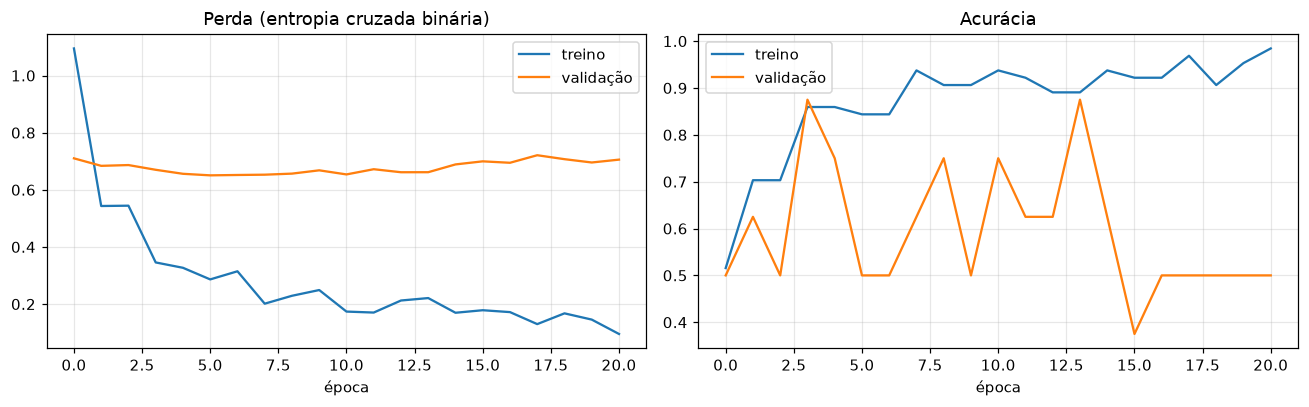

In [26]:
# ---- 5.5.3 Treinamento da CNN ----
EPOCAS_CNN = 60                                                       # teto de épocas (a parada antecipada decide)
parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
inicio = time.perf_counter()
hist_cnn = cnn.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=EPOCAS_CNN, batch_size=16,
                   callbacks=[parada], verbose=0)                      # verbose=0: o histórico é exibido no gráfico abaixo
TEMPO_CNN = time.perf_counter() - inicio
ep_cnn = len(hist_cnn.history["loss"])
print(f"Treinou {ep_cnn} épocas em {TEMPO_CNN / 60:.1f} min; melhor época (menor perda de validação): "
      f"{int(np.argmin(hist_cnn.history['val_loss'])) + 1}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
a1.plot(hist_cnn.history["loss"], label="treino"); a1.plot(hist_cnn.history["val_loss"], label="validação")
a1.set_title("Perda (entropia cruzada binária)"); a1.set_xlabel("época"); a1.legend()
a2.plot(hist_cnn.history["accuracy"], label="treino"); a2.plot(hist_cnn.history["val_accuracy"], label="validação")
a2.set_title("Acurácia"); a2.set_xlabel("época"); a2.legend()
plt.tight_layout(); plt.savefig(PASTA_FIGURAS / "curvas_cnn_do_zero.png", bbox_inches="tight"); plt.show()

Acurácia da CNN – teste (8): 50.0%
Acurácia da CNN – teste extra (40): 50.0%


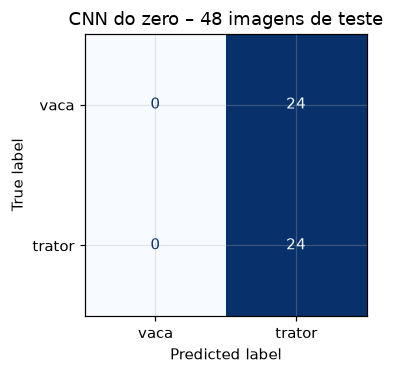

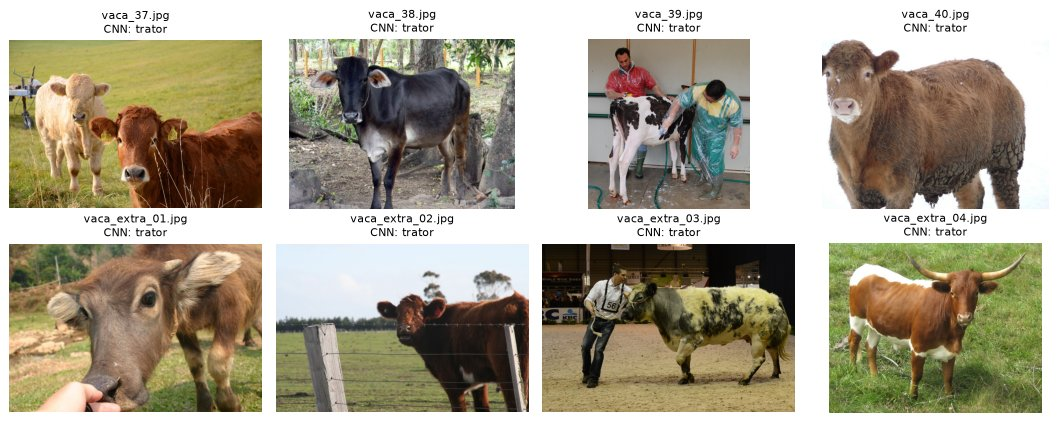

In [27]:
# ---- 5.5.4 Avaliação da CNN nos conjuntos de teste ----
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
X_te, y_te = carregar_classificacao(TODAS)
prob_cnn = cnn.predict(X_te, verbose=0).ravel()                        # probabilidade de trator
PRED_CNN = {p: CLASSES[int(pr >= 0.5)] for p, pr in zip(TODAS, prob_cnn)}
for k, ims in AVAL.items():
    print(f"Acurácia da CNN – {k}: {acuracia(PRED_CNN, ims):.1%}")
fig, ax = plt.subplots(figsize=(4, 3.5))
ConfusionMatrixDisplay(confusion_matrix([classe_real(p) for p in TODAS], [PRED_CNN[p] for p in TODAS], labels=CLASSES),
                       display_labels=CLASSES).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("CNN do zero – 48 imagens de teste"); plt.tight_layout(); plt.show()
erros = [p for p in TODAS if PRED_CNN[p] != classe_real(p)]           # imagens que a CNN errou
if erros:
    grade_imagens(erros[:8], titulos=[f"{p.name}\nCNN: {PRED_CNN[p]}" for p in erros[:8]], colunas=4, tam=3)

### 5.6 Tempo de inferência

Latência de **uma imagem por vez** (o cenário de uma câmera na fazenda), medida com a imagem já decodificada na memória. Para os YOLOs, inclui *letterbox*, rede e NMS; para a CNN, o redimensionamento e a rede. São 5 execuções de aquecimento e depois a média das 48 imagens de teste.

In [28]:
# ---- 5.6 Latência por imagem ----
imagens_mem = [np.asarray(Image.open(p).convert("RGB")) for p in TODAS]   # imagens já carregadas (RGB)

def latencia(funcao):
    for im in imagens_mem[:5]:
        funcao(im)                                                     # aquecimento (alocação de memória, JIT)
    tempos = []
    for im in imagens_mem:
        t0 = time.perf_counter(); funcao(im); tempos.append((time.perf_counter() - t0) * 1000)
    return np.mean(tempos), np.std(tempos)

yolo_custom.conf = yolo_coco.conf = 0.25                               # limiar de uso
with torch.no_grad():
    LAT = {"YOLO customizado": latencia(lambda im: yolo_custom(im, size=TAM_IMG)),
           "YOLO padrão": latencia(lambda im: yolo_coco(im, size=TAM_IMG))}
LAT["CNN do zero"] = latencia(lambda im: cnn(tf.image.resize(im[None].astype(np.float32), (TAM_CNN, TAM_CNN)), training=False))
display(pd.DataFrame(LAT, index=["média (ms)", "desvio (ms)"]).T)

,média (ms),desvio (ms)
YOLO customizado,84.488,11.944
YOLO padrão,108.979,76.403
CNN do zero,57.507,5.456


### 5.7 Quadro comparativo

,acurácia teste (8),acurácia teste extra (40),acurácia total (48),mAP50 (48),recall vaca,recall trator,treino (min),inferência (ms/img),parâmetros (mi)
abordagem,,,,,,,,,
YOLO customizado,100.0%,100.0%,100.0%,0.868,93.5%,100.0%,13.5,84,7.02
YOLO padrão (estrito),50.0%,50.0%,50.0%,0.493,93.5%,0.0%,0.0,109,7.23
YOLO padrão (otimista),100.0%,95.0%,95.8%,0.863,93.5%,77.8%,0.0,109,7.23
CNN do zero,50.0%,50.0%,50.0%,—,—,—,1.0,58,0.39


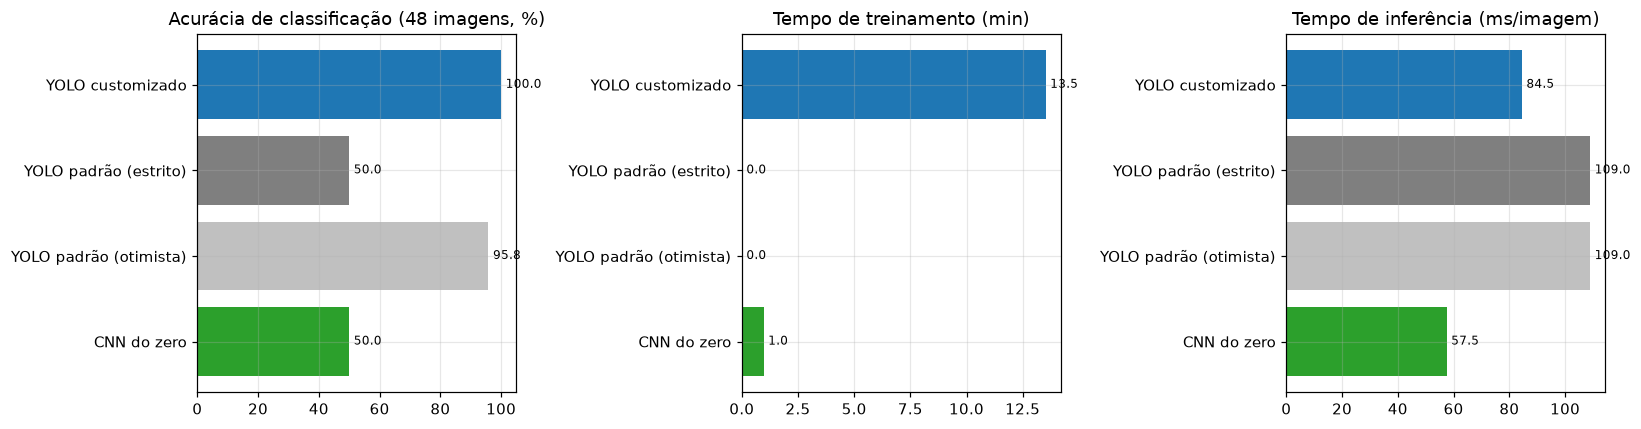

In [29]:
# ---- 5.7 Consolidação: precisão, tempos e parâmetros de cada abordagem ----
n_param = lambda m: sum(p.numel() for p in m.parameters())             # nº de parâmetros de um modelo PyTorch
linhas = []
for nome in ["YOLO customizado", "YOLO padrão (estrito)", "YOLO padrão (otimista)", "CNN do zero"]:
    if nome == "CNN do zero":
        cls, det, treino, lat, params = PRED_CNN, None, TEMPO_CNN, LAT["CNN do zero"][0], cnn.count_params()
    else:
        cls = classificar_por_deteccao(PRED_DET[nome]); det = avaliar_deteccao(PRED_DET[nome], TODAS)
        treino = TREINO[ESCOLHIDO]["segundos"] if nome == "YOLO customizado" else 0.0
        lat = LAT["YOLO customizado" if nome == "YOLO customizado" else "YOLO padrão"][0]
        params = n_param(yolo_custom if nome == "YOLO customizado" else yolo_coco)
    linhas.append({"abordagem": nome,
                   "acurácia teste (8)": acuracia(cls, AVAL["teste (8)"]),
                   "acurácia teste extra (40)": acuracia(cls, AVAL["teste extra (40)"]),
                   "acurácia total (48)": acuracia(cls, TODAS),
                   "mAP50 (48)": det.loc["média", "AP50"] if det is not None else np.nan,
                   "recall vaca": det.loc["vaca", "R"] if det is not None else np.nan,
                   "recall trator": det.loc["trator", "R"] if det is not None else np.nan,
                   "treino (min)": treino / 60, "inferência (ms/img)": lat, "parâmetros (mi)": params / 1e6})
QUADRO = pd.DataFrame(linhas).set_index("abordagem")
QUADRO.to_csv(PASTA_RESULTADOS / "comparativo_entrega2.csv")
display(formatar(QUADRO, {**{c: "{:.1%}" for c in QUADRO.columns if c.startswith(("acur", "recall"))},
                          "treino (min)": "{:.1f}", "inferência (ms/img)": "{:.0f}", "parâmetros (mi)": "{:.2f}"}))

fig, eixos = plt.subplots(1, 3, figsize=(15, 4))
cores = ["tab:blue", "tab:gray", "silver", "tab:green"]
eixos[0].barh(QUADRO.index, QUADRO["acurácia total (48)"] * 100, color=cores); eixos[0].set_title("Acurácia de classificação (48 imagens, %)")
eixos[1].barh(QUADRO.index, QUADRO["treino (min)"], color=cores); eixos[1].set_title("Tempo de treinamento (min)")
eixos[2].barh(QUADRO.index, QUADRO["inferência (ms/img)"], color=cores); eixos[2].set_title("Tempo de inferência (ms/imagem)")
for ax in eixos:
    ax.invert_yaxis()
    for c in ax.containers:
        ax.bar_label(c, fmt="%.1f", padding=3, fontsize=8)
plt.tight_layout(); plt.savefig(PASTA_FIGURAS / "comparativo_entrega2.png", bbox_inches="tight"); plt.show()

### 5.8 Avaliação crítica

**Resultados nas 48 imagens de avaliação (8 do teste + 40 extras):**

| Abordagem | Acurácia (classe da imagem) | mAP@0,5 | Treino | Inferência (CPU) |
|---|---|---|---|---|
| **YOLO customizado** | **100%** | **0,87** | 13,5 min | 84 ms/img |
| YOLO padrão (estrito: só `cow`) | 50% | 0,49 | não se aplica | 109 ms/img |
| YOLO padrão (otimista: `truck` = trator) | 95,8% | 0,86 | não se aplica | 109 ms/img |
| CNN do zero | 50% | não se aplica | 1,0 min | 58 ms/img |

**1. Facilidade de uso e integração**
- **YOLO padrão:** a mais fácil, porque não exige base, rótulos nem treino. Bastam duas linhas (`torch.hub.load` e a chamada do modelo). O limite são as 80 classes do COCO: **ele não tem trator**. Nas 24 fotos de trator, a resposta mais confiante foi `truck` em 12, `person` em 9 (o tratorista) e até `elephant`, `motorcycle` e `train`. Para o cliente, isso significa que a ferramenta pronta resolve o rebanho, mas não a frota.
- **YOLO customizado:** exige o trabalho mais caro do projeto, que é montar e rotular a base com caixas. Depois disso, o treino é um único comando (`train.py`) e a integração é idêntica à do YOLO padrão (mesmo formato de saída e mesma API).
- **CNN do zero:** pede só o rótulo da imagem (nome do arquivo), sem caixas. Em compensação, exige definir a arquitetura, a aumentação e a parada antecipada, e entrega menos: não localiza nem conta objetos.

**2. Precisão**
- O **YOLO customizado** acertou a classe de **todas as 48 imagens**, com mAP@0,5 de 0,87 e recall de 100% nos tratores e de 94% nas vacas. É o único que resolve a tarefa como ela foi definida.
- O **YOLO padrão** só chega perto (95,8% de acurácia e mAP@0,5 de 0,86) no cenário otimista, quando *nós* decidimos que todo `truck` é um trator. Mesmo assim, o recall de tratores cai para 78%, porque muitos tratores são vistos como `person` ou não são vistos. Esse mapeamento também quebraria na fazenda real, onde caminhões de verdade virariam "tratores". No cenário estrito ele acerta só as vacas (50%).
- A **CNN do zero não aprendeu**: respondeu sempre a mesma classe e ficou nos 50% do acaso nas 48 imagens. A perda de validação parou de cair na 6ª época, e a parada antecipada encerrou o treino na 21ª. Com 64 imagens de fotos muito variadas (raças, ângulos, cenários, tratores de todas as cores), uma rede sem nenhum conhecimento prévio não consegue extrair padrões gerais. A validação com só 8 imagens também torna o sinal da parada antecipada muito ruidoso. É exatamente a situação em que *transfer learning* faz diferença, e é o que explica o sucesso das duas YOLOs, que partem dos pesos do COCO.

**3. Tempo de treinamento/customização**
- YOLO padrão: zero.
- CNN do zero: 1 minuto, mas sem resultado útil.
- YOLO customizado: 13,5 minutos em CPU com 320 px e 30 épocas (em GPU seriam poucos minutos), mais o tempo de rotulação, que na prática é o maior custo.

**4. Tempo de inferência**
Na CPU e com uma imagem por vez, a **CNN é a mais rápida (58 ms)**, por ter 0,39 milhão de parâmetros contra cerca de 7 milhões das YOLOs. O YOLO customizado (84 ms) foi um pouco mais rápido que o padrão (109 ms). A arquitetura é praticamente a mesma; a diferença vem da cabeça menor (2 classes × 80) e de um NMS mais leve, com menos caixas candidatas. As três abordagens ficam bem abaixo de 1 segundo por imagem, o que já serve para monitorar câmeras de fazenda (1 quadro a cada poucos segundos) mesmo sem GPU.

**Veredito:** para o cenário da FarmTech, o **YOLO customizado** é a melhor escolha. Ele é o único que reconhece tratores de verdade, também localiza e conta os objetos (útil para contar o rebanho ou ver se a máquina saiu do galpão) e roda em tempo aceitável em CPU. O **YOLO padrão** é um bom ponto de partida para classes que já existem no COCO (as vacas) e serve como *baseline* gratuito. A **CNN do zero**, com uma base deste tamanho, não é uma alternativa viável. Ela só faria sentido com centenas de imagens por classe ou partindo de uma rede pré-treinada.

## 6. Conclusões, pontos fortes e limitações

**Principais achados**
- Uma YOLOv5s customizada com apenas **64 imagens de treino** e 30 épocas chegou a **mAP@0,5 de 0,95 no teste** e acertou a classe de **100% das 48 imagens de avaliação**. É uma demonstração convincente para o cliente de que visão computacional sob medida é viável com uma base pequena.
- O número de épocas importa muito nesse regime de poucos dados: 15 épocas deixaram o modelo inutilizável (mAP@0,5 de 0,12 no teste), enquanto 30 o tornaram confiável.
- Modelos prontos (YOLO do COCO) resolvem o que já conhecem (vacas), mas não generalizam para objetos fora do vocabulário (tratores). Treinar uma rede do zero com poucas imagens não funciona. O caminho eficiente é o **transfer learning com customização**.

**Pontos fortes do trabalho**
- Base curada manualmente, com fotos reais e variadas (raças, poses, tratores antigos e modernos, neve, exposições, implementos), licença aberta e créditos documentados.
- Protocolo de comparação justo: mesmas imagens, mesma função de métrica para os dois detectores, latência medida no mesmo hardware e um **teste extra de 40 imagens** além do teste do enunciado, para reduzir o peso do acaso.
- Notebook reprodutível: monta o Drive no Colab, baixa a base do GitHub quando ela não está no Drive, usa sementes fixas e guarda os logs completos e os artefatos em `resultados/`.

**Limitações**
- **Base pequena:** 4 imagens de teste por classe é pouco, e cada erro vale 12,5 pontos percentuais. O teste extra ameniza, mas os números ainda têm incerteza alta.
- **Treino reduzido por falta de GPU:** a execução foi feita em CPU, com 320 px e 15 × 30 épocas, em vez de 640 px e 30 × 60. As curvas mostram que o modelo de 30 épocas ainda não tinha convergido, então o resultado com mais épocas e resolução maior tende a ser melhor, principalmente no mAP@0,5:0,95.
- **Rótulos:** as caixas de vaca vêm do Open Images e as de trator foram sugeridas pelo YOLO-World e corrigidas à mão. A revisão final caixa a caixa no Make Sense não foi concluída, e algumas caixas pequenas de animais ao fundo podem estar faltando.
- **Fotos da internet, não da fazenda do cliente:** câmeras de segurança fixas, à noite ou com chuva, produziriam imagens bem diferentes. Seria preciso coletar e rotular imagens do próprio ambiente antes de colocar em produção.
- A CNN do zero foi avaliada com uma única configuração. Mais aumentação, uma rede menor ou validação cruzada poderiam tirá-la do colapso, mas dificilmente a aproximariam da YOLO com esta quantidade de dados.

**Próximos passos:** treinar com GPU (640 px, 60 ou mais épocas), ampliar a base com imagens das câmeras do cliente, rotular as classes de interesse para saúde animal (animal deitado, cocho, cerca) e testar o modelo em vídeo ao vivo com uma ESP32-CAM ou webcam.

## 7. Salvando os resultados no Drive

Os arquivos gerados pelo YOLOv5 ficam em `yolov5/runs`, que no Colab é apagado ao fim da sessão. A célula abaixo copia o essencial para `resultados/` (no Drive, quando executado no Colab): curvas, métricas, matrizes de confusão, imagens processadas e os pesos finais.

In [30]:
# ---- 7. Cópia dos artefatos para a pasta de resultados ----
DEST = PASTA_RESULTADOS / "yolov5"
for origem in ["runs/train/treino_15ep", "runs/train/treino_30ep", "runs/val/val_15ep", "runs/val/val_30ep",
               "runs/val/teste_15ep", "runs/val/teste_30ep", "runs/detect/teste_15ep", "runs/detect/teste_30ep",
               "runs/detect/teste_yolo_padrao"]:
    o = PASTA_YOLO / origem
    shutil.copytree(o, DEST / origem.replace("runs/", ""), dirs_exist_ok=True,
                    ignore=shutil.ignore_patterns("weights", "*.cache"))  # pesos copiados à parte (só o escolhido)
(PASTA_RESULTADOS / "modelos").mkdir(exist_ok=True)
shutil.copy(TREINO[ESCOLHIDO]["best"], PASTA_RESULTADOS / "modelos" / "yolov5s_vaca_trator_best.pt")   # usado no "Ir Além"
cnn.save(PASTA_RESULTADOS / "modelos" / "cnn_do_zero.keras")
tab_comp.to_csv(PASTA_RESULTADOS / "comparativo_15x30_epocas.csv")
print("Arquivos salvos em", PASTA_RESULTADOS)
for p in sorted(PASTA_RESULTADOS.glob("*")):
    print("  ", p.name)

Arquivos salvos em D:\FIAP\fase_6_cap_1\resultados
   comparativo_15x30_epocas.csv
   comparativo_entrega2.csv
   data.yaml
   logs
   modelos
   yolov5


## 8. Referências e créditos das imagens

- JOCHER, G. et al. **YOLOv5 by Ultralytics**. GitHub, 2020. Disponível em: https://github.com/ultralytics/yolov5.
- REDMON, J. et al. **You Only Look Once: Unified, Real-Time Object Detection**. CVPR, 2016.
- LIN, T.-Y. et al. **Microsoft COCO: Common Objects in Context**. ECCV, 2014.
- KUZNETSOVA, A. et al. **The Open Images Dataset V4**. IJCV, 2020. Imagens: https://storage.googleapis.com/openimages/web/index.html.
- CHENG, T. et al. **YOLO-World: Real-Time Open-Vocabulary Object Detection**. CVPR, 2024 (usado apenas para sugerir pré-rótulos de tratores).
- SKALSKI, P. **Make Sense**. Disponível em: https://www.makesense.ai.
- CHOLLET, F. **Deep Learning with Python**. 2. ed. Manning, 2021.

**Créditos das imagens:** todas as fotos são do Open Images V7 / Flickr, licença [CC BY 2.0](https://creativecommons.org/licenses/by/2.0/). Autor, título e link de cada uma estão em `creditos_imagens.csv`.